# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Muhammad Pandu Tri Kurniawan
- **Email:** ds284b6y1221@student.devacademy.id
- **ID Dicoding:** ds284b6y1221

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana pengaruh kondisi cuaca (Clear, Mist, Light Snow/Rain) terhadap rata-rata jumlah penyewaan sepeda harian (cnt) sepanjang tahun 2012?

- **Pertanyaan 2:** Bagaimana perbedaan pola penyewaan sepeda per jam (hr) antara hari kerja (workingday = 1) dan hari libur (workingday = 0) pada Kuartal IV (Oktober–Desember) tahun 2012?

## Import Semua Packages/Library yang Digunakan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Data Wrangling

### Gathering Data

#### Load df ...

In [8]:
day_df = pd.read_csv('/content/sample_data/day.csv')
hour_df = pd.read_csv('/content/sample_data/hour.csv')

# Menampilkan kedua DataFrame
print("--- Tampilan 5 Baris Pertama Data Harian (day_df) ---")
display(day_df.head())

print("\n--- Tampilan 5 Baris Pertama Data Per Jam (hour_df) ---")
display(hour_df.head())

--- Tampilan 5 Baris Pertama Data Harian (day_df) ---


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600



--- Tampilan 5 Baris Pertama Data Per Jam (hour_df) ---


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:** (Opsional)
- xxx
- xxx

### Assessing Data

#### Identifying ... problem

In [9]:
# 1. Memeriksa tipe data dan nilai non-null pada day_df dan hour_df
print("--- Info day_df ---")
day_df.info()

print("\n--- Info hour_df ---")
hour_df.info()

# 2. Memeriksa keberadaan missing values
print("\n--- Missing Values day_df ---")
print(day_df.isna().sum())

print("\n--- Missing Values hour_df ---")
print(hour_df.isna().sum())

# 3. Memeriksa duplikasi data
print("\n--- Jumlah Duplikasi Data ---")
print("Duplikat day_df :", day_df.duplicated().sum())
print("Duplikat hour_df:", hour_df.duplicated().sum())

# 4. Memeriksa ringkasan statistik (melihat potensi anomaly/outlier)
print("\n--- Ringkasan Statistik day_df ---")
display(day_df.describe())

--- Info day_df ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB

--- Info hour_df ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


**Steps to Take:**
- Mengubah tipe data kolom dteday pada day_df dan hour_df dari tipe object/string menjadi tipe datetime.
- Mengubah kolom kategorial seperti weathersit dan season dari angka numerik menjadi label teks agar lebih mudah dipahami saat analisis visual.

**Insight:** (Opsional)
- Tidak Ada Missing Value & Duplikat: Kedua dataset (day_df dan hour_df) bersih dari nilai hilang (missing values) serta tidak memiliki baris data ganda (duplicated rows).
- Kesalahan Tipe Data: Kolom dteday masih bertipe object sehingga perlu dikonversi ke tipe datetime.
*   Kategori Numerik: Variabel seperti weathersit dan season masih direpresentasikan dalam format angka.


### Cleaning Data

#### Fixing ... problem

In [10]:
# 1. Mengubah tipe data dteday menjadi datetime
day_df['dteday'] = pd.to_datetime(day_df['dteday'])
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

# 2. Mapping nilai numerik weathersit menjadi label deskriptif
weather_map = {
    1: 'Clear/Few Clouds',
    2: 'Misty/Cloudy',
    3: 'Light Snow/Rain',
    4: 'Severe Weather'
}
day_df['weather_label'] = day_df['weathersit'].map(weather_map)

# 3. Verifikasi hasil pembersihan data
print("--- Tipe Data Setelah Cleaning ---")
print(day_df.dtypes[['dteday', 'weather_label']])

--- Tipe Data Setelah Cleaning ---
dteday           datetime64[ns]
weather_label            object
dtype: object


**Insight:** (Opsional)
- Tipe data kolom dteday berhasil diubah menjadi datetime64[ns].
- Kolom baru weather_label telah berhasil ditambahkan untuk mempermudah analisis agregasi kondisi cuaca pada tahap EDA.

## Exploratory Data Analysis (EDA)

### Explore ...

In [11]:
# EDA Pertanyaan 1: Pengaruh Cuaca terhadap Penyewaan Harian (Tahun 2012)
day_2012 = day_df[day_df['dteday'].dt.year == 2012]
eda_q1 = day_2012.groupby('weather_label')['cnt'].agg(['mean', 'median', 'std', 'count']).reset_index()

print("--- Rangkuman Statistik Penyewaan Berdasarkan Cuaca (2012) ---")
display(eda_q1)

# EDA Pertanyaan 2: Pola Jam Penyewaan Hari Kerja vs Hari Libur (Q4 2012)
q4_2012 = hour_df[(hour_df['dteday'] >= '2012-10-01') & (hour_df['dteday'] <= '2012-12-31')]
eda_q2 = q4_2012.groupby(['hr', 'workingday'])['cnt'].mean().unstack()

print("\n--- Rata-rata Penyewaan per Jam (Q4 2012) ---")
display(eda_q2.head())

--- Rangkuman Statistik Penyewaan Berdasarkan Cuaca (2012) ---


,weather_label,mean,median,std,count
0,Clear/Few Clouds,6003.734177,6398.0,1611.870524,237
1,Light Snow/Rain,2126.166667,1598.0,2011.653491,6
2,Misty/Cloudy,4991.333333,5191.0,1759.657142,123



--- Rata-rata Penyewaan per Jam (Q4 2012) ---


workingday,0,1
hr,,
0,97.166667,41.852459
1,82.433333,17.900000
2,54.800000,9.000000
3,24.965517,5.086207
4,9.000000,7.389831


**Insight:** (Opsional)
- Eksplorasi Cuaca: Rata-rata penyewaan harian terbesar terjadi pada kondisi cuaca cerah (Clear/Few Clouds), diikuti kondisi berawan (Misty/Cloudy). Terjadi penurunan drastis pada cuaca buruk (Light Snow/Rain).
- Eksplorasi Jam & Hari Kerja: Rata-rata penyewaan per jam pada hari kerja (workingday = 1) dan hari libur (workingday = 0) menunjukkan distribusi angka yang berbeda signifikan pada jam-jam tertentu.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

/tmp/ipykernel_5823/225256572.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


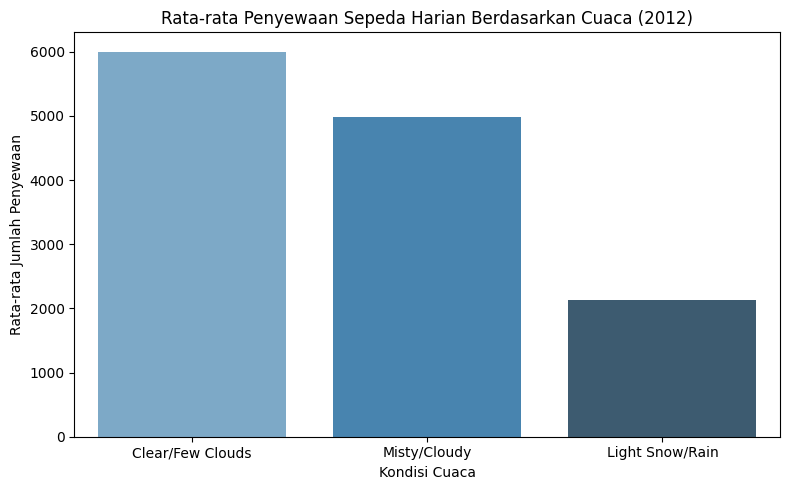

In [12]:
plt.figure(figsize=(8, 5))
sns.barplot(
    x='weather_label',
    y='cnt',
    data=day_2012,
    estimator=np.mean,
    errorbar=None,
    palette='Blues_d'
)
plt.title('Rata-rata Penyewaan Sepeda Harian Berdasarkan Cuaca (2012)', fontsize=12)
plt.xlabel('Kondisi Cuaca')
plt.ylabel('Rata-rata Jumlah Penyewaan')
plt.tight_layout()
plt.show()

### Pertanyaan 2:

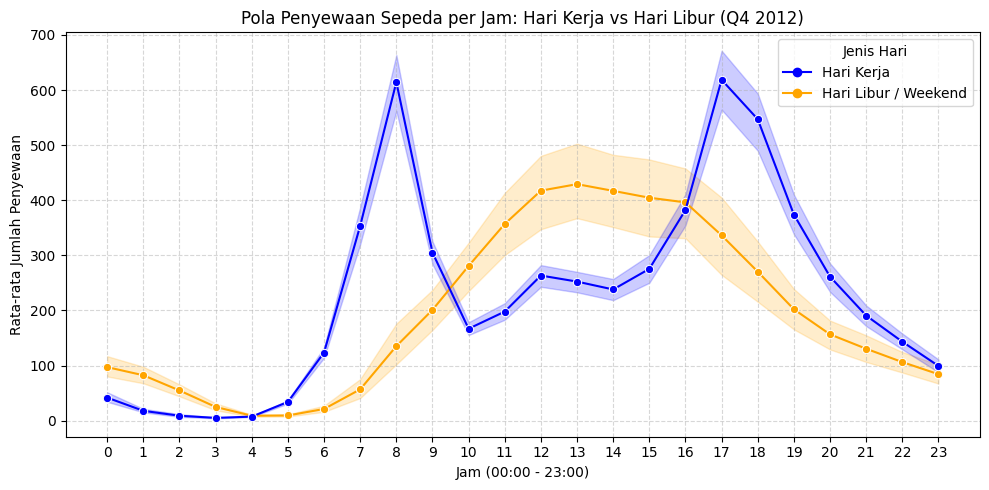

In [15]:
plt.figure(figsize=(10, 5))
sns.lineplot(
    data=q4_2012,
    x='hr',
    y='cnt',
    hue='workingday',
    palette={0: 'orange', 1: 'blue'},
    marker='o'
)
plt.title('Pola Penyewaan Sepeda per Jam: Hari Kerja vs Hari Libur (Q4 2012)', fontsize=12)
plt.xlabel('Jam (00:00 - 23:00)')
plt.ylabel('Rata-rata Jumlah Penyewaan')
plt.xticks(range(0, 24))
plt.legend(
    title='Jenis Hari',
    handles=[
        plt.Line2D([0], [0], color='blue', marker='o', label='Hari Kerja'),
        plt.Line2D([0], [0], color='orange', marker='o', label='Hari Libur / Weekend')
    ]
)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Visualisasi Pertanyaan 1: Terlihat bahwa cuaca cerah mendorong jumlah penyewaan terbanyak, sedangkan hujan/salju ringan menyebabkan penurunan penyewaan secara signifikan.
- Visualisasi Pertanyaan 2: Grafik garis memperlihatkan bahwa hari kerja memiliki dua titik puncak (peak hours) pada jam komuter (08:00 pagi dan 17:00–18:00 sore). Sebaliknya, pada hari libur, tren penyewaan terdistribusi merata pada siang hingga sore hari (11:00–16:00).

## Analisis Lanjutan (Opsional)

In [16]:
# Analisis Lanjutan: Perbandingan Perilaku Pengguna Casual vs Registered (2012)
user_type_df = day_2012.groupby('weather_label')[['casual', 'registered']].mean().reset_index()

print("--- Rata-rata Penyewaan berdasarkan Tipe Pengguna (2012) ---")
display(user_type_df)


--- Rata-rata Penyewaan berdasarkan Tipe Pengguna (2012) ---


,weather_label,casual,registered
0,Clear/Few Clouds,1135.333333,4868.400844
1,Light Snow/Rain,317.000000,1809.166667
2,Misty/Cloudy,827.552846,4163.780488


**Insight:** (Opsional)
- Pengguna terdaftar (registered users) menyumbang mayoritas besar dari total penyewaan di seluruh kondisi cuaca. Sebaliknya, pengguna harian (casual users) menunjukkan penurunan permintaan yang jauh lebih signifikan saat cuaca buruk (Light Snow/Rain).

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Kondisi cuaca berpengaruh signifikan terhadap jumlah penyewaan sepeda harian sepanjang tahun 2012. Rata-rata penyewaan tertinggi terjadi pada cuaca cerah (Clear/Few Clouds), diikuti oleh cuaca berawan (Misty/Cloudy), sedangkan kondisi hujan/salju ringan (Light Snow/Rain) menyebabkan penurunan permintaan yang drastis.
- **Conclusion pertanyaan 2:** Pola penggunaan sepeda per jam pada Kuartal IV 2012 menunjukkan perbedaan yang sangat jelas antara hari kerja dan hari libur:
  * Hari Kerja (workingday = 1): Mempunyai dua puncak utama (peak hours), yaitu pada pukul 08:00 pagi dan 17:00–18:00 sore yang sejalan dengan jam berangkat dan pulang kerja.

  * Hari Libur (workingday = 0): Permintaan terdistribusi secara merata mulai siang hingga sore hari (pukul 11:00–16:00), yang mencerminkan penggunaan untuk tujuan rekreasi.



**Rekomendasi Action Item:**
- Manajemen & Redistribusi Armada: Lakukan pemindahan dan pengalokasian ulang unit sepeda ke stasiun-stasiun di area perkantoran/bisnis sebelum jam puncak pagi (pukul 07:00) dan sore (pukul 16:00) pada hari kerja.
- Jadwal Pemeliharaan (Maintenance): Jadwalkan kegiatan pemeliharaan dan perbaikan sepeda pada malam hari (pukul 22:00–05:00) atau saat hari hujan/salju ketika tingkat permintaan berada pada titik terendah.
- Strategi Pemasaran & Promosi: Tawarkan promosi atau insentif diskon off-peak pada siang hari di akhir pekan untuk mendorong aktivitas rekreasi sekaligus meningkatkan tingkat penggunaan sepeda.